# Tugas Praktikum 3 - Classification dengan Ensemble Method & Class Imbalance

| | |
|---|---|
| **Nama** | Rasya Arya Ramadhan |
| **NRP** | 5054251019 |
| **Mata Kuliah** | Data Mining |
| **Dataset** | Credit Card Fraud Detection (Kaggle) |

Di praktikum ini saya bikin model buat deteksi transaksi kartu kredit yang penipuan, pakai ensemble method. Dua algoritma yang saya pakai Random Forest (perwakilan bagging) dan XGBoost (perwakilan boosting).

Kendala utama di dataset ini ada di distribusi kelasnya. Transaksi fraud cuma 492 baris dari 284.807, atau sekitar 0,17%. Karena itu selain modelnya, saya juga nyoba beberapa cara buat ngatasin class imbalance, terus dibandingin hasilnya.

**Alur praktikum:**

1. Load dataset dan cek distribusi kelas
2. Praproses: scaling dan splitting stratify
3. Penanganan imbalance pakai SMOTE dan class weighting
4. Modeling pakai Random Forest dan XGBoost, masing-masing dalam 3 skenario
5. Evaluasi pakai precision, recall, F1, ROC-AUC, PR-AUC, dan confusion matrix

## 1. Import Library

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, matthews_corrcoef,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay,
)

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)
print("Library siap dipakai.")

Library siap dipakai.


## 2. Load Dataset

Dataset diambil dari Kaggle *Credit Card Fraud Detection*. Isinya 284.807 transaksi dengan 31 kolom, di mana kolom `Class` itu labelnya: **0 = transaksi normal, 1 = transaksi penipuan**.

In [2]:
df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Jumlah baris x kolom :", df.shape)
print("Total missing value  :", df.isna().sum().sum())
print("Duplikat baris       :", df.duplicated().sum())
print("\nTipe data:")
print(df.dtypes.value_counts())
print("\nStatistik singkat:")
df[["Time", "Amount", "Class"]].describe().T

Jumlah baris x kolom : (284807, 31)
Total missing value  : 0


Duplikat baris       : 1081

Tipe data:
float64    30
int64       1
Name: count, dtype: int64

Statistik singkat:


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


Dari 31 kolom itu, yang `V1` sampai `V28` hasil transformasi PCA, jadi nama kolomnya memang udah nggak bisa ditelusuri lagi ke arti aslinya. Data aslinya udah dianonimkan sama pihak penyedia dataset.

Kolom yang masih bisa dibaca cuma tiga:
- **`Time`**: jarak dalam detik dari transaksi pertama
- **`Amount`**: nilai transaksinya
- **`Class`**: label target

Satu hal yang perlu dicatat, nggak ada missing value sama sekali di dataset ini. Jadi langkah pembersihan data bisa dibilang nggak terlalu banyak, fokusnya lebih ke masalah imbalance sama scaling dua kolom terakhir.

## 3. Distribusi Kelas

In [4]:
jumlah = df["Class"].value_counts().sort_index()
persen = df["Class"].value_counts(normalize=True).sort_index() * 100

tabel_kelas = pd.DataFrame({
    "Kelas": ["0 (Normal)", "1 (Fraud)"],
    "Jumlah": jumlah.values,
    "Persentase": [f"{p:.4f}%" for p in persen.values],
    "Rasio terhadap kelas mayoritas": ["1 : 1", f"1 : {jumlah[0]/jumlah[1]:.0f}"],
})
tabel_kelas

,Kelas,Jumlah,Persentase,Rasio terhadap kelas mayoritas
0,0 (Normal),284315,99.8273%,1 : 1
1,1 (Fraud),492,0.1727%,1 : 578


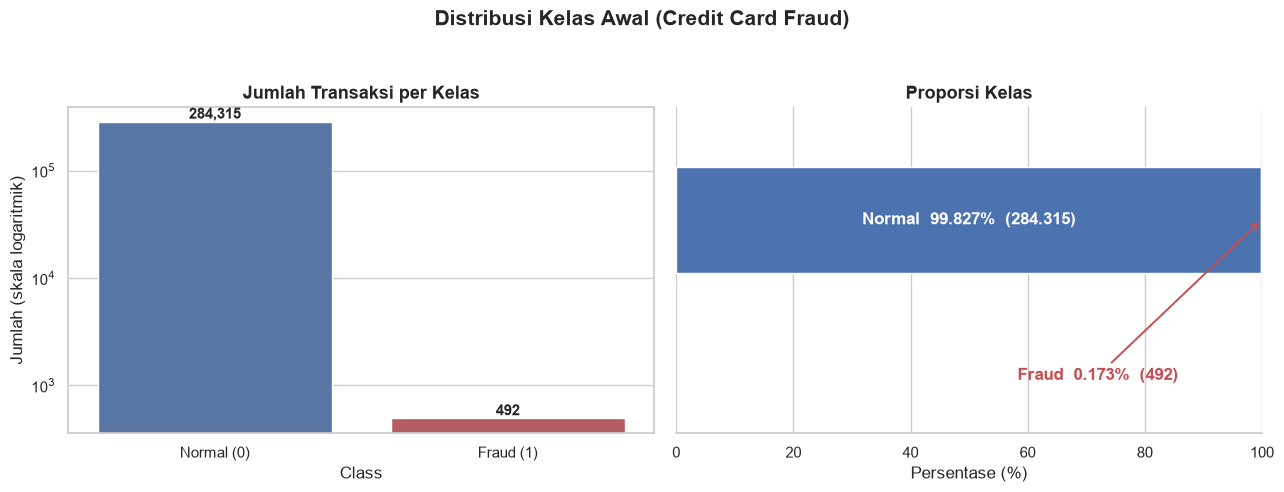

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(x=df["Class"], palette=["#4c72b0", "#c44e52"], ax=axes[0])
axes[0].set_title("Jumlah Transaksi per Kelas", fontsize=13, weight="bold")
axes[0].set_xticklabels(["Normal (0)", "Fraud (1)"])
axes[0].set_yscale("log")
axes[0].set_ylabel("Jumlah (skala logaritmik)")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha="center", va="bottom", fontsize=11, weight="bold")

ax = axes[1]
ax.barh([0], [99.8273], color="#4c72b0", height=0.42)
ax.barh([0], [0.1727], left=[99.8273], color="#c44e52", height=0.42)
ax.annotate("Fraud  0.173%  (492)", xy=(99.9, 0), xytext=(72, -0.62),
            arrowprops=dict(arrowstyle="->", color="#c44e52", lw=1.4),
            color="#c44e52", fontsize=12, ha="center", va="center", weight="bold")
ax.text(50, 0, "Normal  99.827%  (284.315)", color="white", fontsize=12,
        ha="center", va="center", weight="bold")
ax.set_xlim(0, 100); ax.set_ylim(-0.85, 0.45)
ax.set_yticks([]); ax.set_xlabel("Persentase (%)")
ax.set_title("Proporsi Kelas", fontsize=13, weight="bold")
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)

plt.suptitle("Distribusi Kelas Awal (Credit Card Fraud)", fontsize=15, weight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("figures/fig1_distribusi_kelas.png", dpi=150, bbox_inches="tight")
plt.show()

Selisihnya kelihatan banget: **284.315 normal berbanding 492 fraud**. Fraunya itu cuma 0,17% dari total data, atau kira-kira 1 fraud tiap 578 transaksi normal.

Nah di sinilah masalahnya mulai kelihatan. Kalau modelnya cuma diminta *seakurat mungkin*, cara paling gampang buat dapet akurasi tinggi justru dengan nebak semua transaksi sebagai normal. Secara teknis itu namanya *accuracy paradox*, angka akurasinya bagus, tapi modelnya sama sekali nggak guna buat tujuan awalnya.

Coba saya buktiin dengan model paling sederhana, `DummyClassifier`, yang strateginya cuma satu: selalu prediksi kelas mayoritas.

In [6]:
X_all = df.drop(columns=["Class"])
y_all = df["Class"]

Xtr_d, Xte_d, ytr_d, yte_d = train_test_split(
    X_all, y_all, test_size=0.2, random_state=RANDOM_STATE, stratify=y_all
)

dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy.fit(Xtr_d, ytr_d)
pred_dummy = dummy.predict(Xte_d)

acc_dummy = accuracy_score(yte_d, pred_dummy)
print(f"Akurasi model dummy : {acc_dummy:.4f}  ({acc_dummy*100:.2f}%)")
print("\nClassification report:")
print(classification_report(yte_d, pred_dummy, zero_division=0,
                            target_names=["Normal", "Fraud"]))

Akurasi model dummy : 0.9983  (99.83%)

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.00      0.00      0.00        98

    accuracy                           1.00     56962
   macro avg       0.50      0.50      0.50     56962
weighted avg       1.00      1.00      1.00     56962



Hasilnya persis kayak yang diduga. Model yang **nggak belajar apa-apa** tetep bisa dapet akurasi 99,83%. Tapi kalau dilihat recall-nya di kelas fraud, nilainya **0.00**, artinya dari 98 transaksi penipuan di data uji, nol yang ke-deteksi.

Jadi angka akurasi di kasus ini jelas nggak bisa dipakai sebagai patokan. Yang harus dilihat justru precision, recall, F1, dan AUC-ROC.

## 4. Praproses Data

### 4.1. Scaling kolom `Time` dan `Amount`

Kolom `V1`–`V28` hasil PCA biasanya udah punya rentang yang relatif sebanding, jadi nggak saya ubah lagi. Yang saya scale cuma `Time` dan `Amount`, karena rentangnya jauh lebih lebar.

Scaler yang dipakai `RobustScaler`, bukan `StandardScaler`. Alasannya kolom `Amount` itu banyak banget outliernya, mayoritas transaksi nilainya kecil, tapi ada transaksi besar yang nilainya beribu kali lipat. `RobustScaler` ngitung berdasarkan median dan IQR, jadi nggak gampang ketarik outlier kayak gitu.

### 4.2. Splitting data

Pembagiannya 80:20 dengan `stratify=y`. Parameter `stratify` ini penting, tanpa itu proporsi fraud di data latih dan data uji bisa nggak sama, dan karena kelas fraudnya cuma 492 baris, perbedaan sedikit aja udah berarti.

In [7]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = RobustScaler()
X_train[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time", "Amount"]])
X_test[["Time", "Amount"]] = scaler.transform(X_test[["Time", "Amount"]])

print(f"Data latih : {X_train.shape}  -> {Counter(y_train)}")
print(f"Data uji   : {X_test.shape}  -> {Counter(y_test)}")

Data latih : (227845, 30)  -> Counter({0: 227451, 1: 394})
Data uji   : (56962, 30)  -> Counter({0: 56864, 1: 98})


## 5. Penanganan Class Imbalance

Dari beberapa cara yang dibahas di modul (resampling, weighted loss, cost-sensitive learning, sampai anomaly detection), di sini saya coba dua pendekatan:

1. **SMOTE** (*Synthetic Minority Over-sampling Technique*): bikin data fraud sintetis di data latih supaya jumlah kelasnya imbang.
2. **Class weighting**: nggak nambah data, tapi modelnya dikasih "denda" lebih besar kalau salah nangkep fraud.

**Satu hal yang penting banget:** resampling cuma boleh dilakukan di **data latih**. Kalau data uji juga di-SMOTE, nanti hasil evaluasinya nggak nyata, soalnya di dunia nyata kita nggak pernah punya data fraud yang jumlahnya udah dibikin imbang.

Makanya pembagiannya tadi udah saya lakukan sebelum SMOTE.

In [8]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Sebelum SMOTE : {Counter(y_train)}")
print(f"Sesudah SMOTE : {Counter(y_train_res)}")

Sebelum SMOTE : Counter({0: 227451, 1: 394})
Sesudah SMOTE : Counter({0: 227451, 1: 227451})


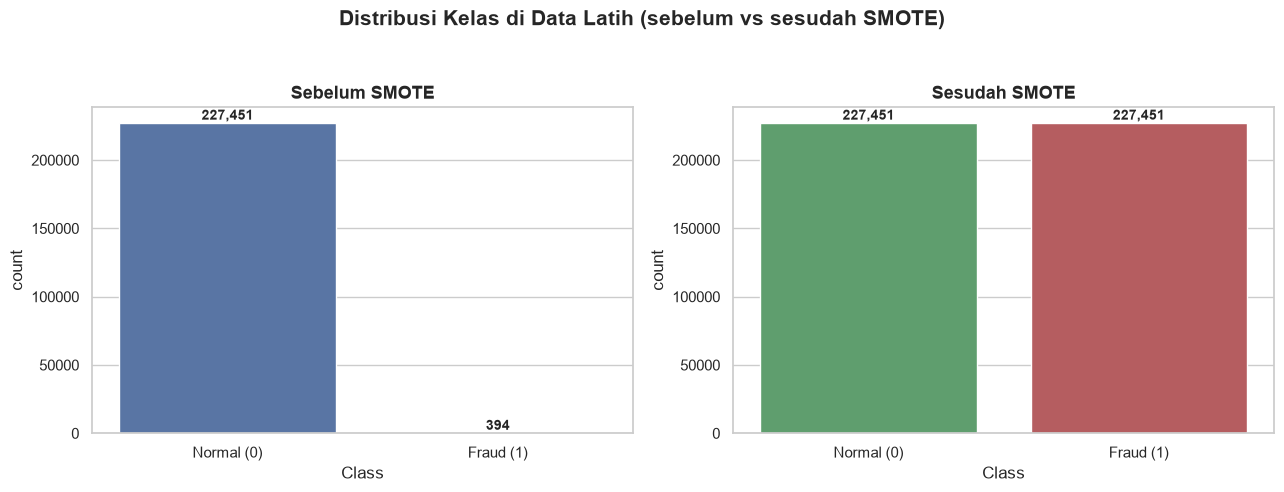

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(x=y_train, palette=["#4c72b0", "#c44e52"], ax=axes[0])
axes[0].set_title("Sebelum SMOTE", fontsize=13, weight="bold")
axes[0].set_xticklabels(["Normal (0)", "Fraud (1)"])

sns.countplot(x=y_train_res, palette=["#55a868", "#c44e52"], ax=axes[1])
axes[1].set_title("Sesudah SMOTE", fontsize=13, weight="bold")
axes[1].set_xticklabels(["Normal (0)", "Fraud (1)"])

for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height()):,}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha="center", va="bottom", fontsize=10, weight="bold")

plt.suptitle("Distribusi Kelas di Data Latih (sebelum vs sesudah SMOTE)",
             fontsize=15, weight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("figures/fig2_smote.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Modeling Ensemble

Dua algoritma ensemble yang saya pakai:

- **Random Forest** (bagging): tiap pohon dilatih di subset data hasil *bootstrap*, lalu hasilnya di-voting. Random Forest umumnya stabil dan nggak gampang overfit.
- **XGBoost** (boosting): tiap pohon berurutan belajar dari kesalahan pohon sebelumnya. Biasanya lebih tajam, tapi juga lebih sensitif terhadap data yang timpang.

Tiap algoritma saya jalanin dalam **3 skenario**, jadi total 6 model:

| Skenario | Cara ngatasin imbalance |
|---|---|
| Tanpa penanganan | Model dilatih apa adanya, jadi pembanding dasar |
| SMOTE | Dilatih di data latih yang udah di-resample |
| Class weighting | `class_weight="balanced"` (RF) / `scale_pos_weight` (XGBoost) |

In [10]:
hasil = {}

def evaluasi(nama, model, X_tr, y_tr, X_te, y_te):
    # Latih model, lalu simpan semua metriknya ke dict hasil
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    cm = confusion_matrix(y_te, pred)

    hasil[nama] = {
        "model": model, "pred": pred, "proba": proba, "cm": cm,
        "Accuracy": accuracy_score(y_te, pred),
        "Balanced Acc": balanced_accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred, zero_division=0),
        "F1-Score": f1_score(y_te, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_te, proba),
        "PR-AUC": average_precision_score(y_te, proba),
        "MCC": matthews_corrcoef(y_te, pred),
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1],
    }
    print(f"  {nama} selesai")
    return hasil[nama]

### 6.1. Random Forest

`class_weight="balanced"` di Random Forest itu otomatis ngitung bobotnya dari frekuensi kelas, jadi kelas fraud bakal dapet bobot lebih besar waktu split pohon.

In [11]:
rf_param = dict(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

print("Random Forest:")
evaluasi("RF Tanpa Penanganan",
         RandomForestClassifier(**rf_param), X_train, y_train, X_test, y_test)
evaluasi("RF + SMOTE",
         RandomForestClassifier(**rf_param), X_train_res, y_train_res, X_test, y_test)
evaluasi("RF + Class Weight",
         RandomForestClassifier(**rf_param, class_weight="balanced"),
         X_train, y_train, X_test, y_test)

Random Forest:


  RF Tanpa Penanganan selesai


  RF + SMOTE selesai


  RF + Class Weight selesai


{'model': RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42),
 'pred': array([0, 0, 0, ..., 0, 0, 0], shape=(56962,)),
 'proba': array([0.  , 0.  , 0.01, ..., 0.  , 0.  , 0.  ], shape=(56962,)),
 'cm': array([[56856,     8],
        [   21,    77]]),
 'Accuracy': 0.9994908886626171,
 'Balanced Acc': 0.8927867995819599,
 'Precision': 0.9058823529411765,
 'Recall': 0.7857142857142857,
 'F1-Score': 0.8415300546448088,
 'ROC-AUC': 0.9573101557026863,
 'PR-AUC': 0.862939836265611,
 'MCC': 0.843414022099618,
 'TN': np.int64(56856),
 'FP': np.int64(8),
 'FN': np.int64(21),
 'TP': np.int64(77)}

### 6.2. XGBoost

Buat XGBoost, setara dari `class_weight` itu namanya `scale_pos_weight`. Nilainya rasio jumlah kelas mayoritas terhadap kelas minoritas.

Selain itu parameter `max_depth`, `subsample`, dan `colsample_bytree` saya batasi biar pohonnya nggak terlalu dalam. Kalau nggak dibatasi, boosting gampang banget hafal data fraud yang cuma 394 baris itu.

In [12]:
n_pos = int((y_train == 1).sum())
n_neg = int((y_train == 0).sum())
spw = n_neg / n_pos
print(f"Rasio kelas (scale_pos_weight) = {spw:.2f}")

xgb_param = dict(
    n_estimators=100, learning_rate=0.1, max_depth=5,
    subsample=0.8, colsample_bytree=0.8,
    random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss",
)

print("\nXGBoost:")
evaluasi("XGB Tanpa Penanganan",
         XGBClassifier(**xgb_param), X_train, y_train, X_test, y_test)
evaluasi("XGB + SMOTE",
         XGBClassifier(**xgb_param), X_train_res, y_train_res, X_test, y_test)
evaluasi("XGB + scale_pos_weight",
         XGBClassifier(**xgb_param, scale_pos_weight=spw),
         X_train, y_train, X_test, y_test)

Rasio kelas (scale_pos_weight) = 577.29

XGBoost:


  XGB Tanpa Penanganan selesai


  XGB + SMOTE selesai


  XGB + scale_pos_weight selesai


{'model': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=0.8, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric='logloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=0.1, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=5, max_leaves=None,
               min_child_weight=None, missing=nan, monotone_constraints=None,
               multi_strategy=None, n_estimators=100, n_jobs=-1,
               num_parallel_tree=None, ...),
 'pred': array([0, 0, 0, ..., 0, 0, 0], shape=(56962,)),
 'proba': array([2.7177215e-04, 3.5260664e-04, 4.5008448e-04, ..., 7.0722577e-05,
        5.9405429e-04, 1.0225042e-03], shape=(56962,), dtype=float32

## 7. Evaluasi Model

Sebelum masuk ke angkanya, kenapa dipilih metrik-metrik ini:

- **Precision**: dari yang diprediksi fraud, berapa yang beneran fraud. Rendah di sini artinya investigator bakal kerepotan ngecek alarm palsu.
- **Recall**: dari yang beneran fraud, berapa yang ke-deteksi. Ini yang paling krusial, karena fraud yang lolos itu langsung jadi kerugian nyata.
- **F1-Score**: rata-rata harmonik precision dan recall.
- **ROC-AUC**: seberapa baik model ngebedain kedua kelas, nggak tergantung satu threshold aja.
- **PR-AUC**: serupa ROC-AUC tapi fokus ke kelas minoritas. Di data yang super timpang gini, PR-AUC justru lebih jujur daripada ROC-AUC.

In [13]:
tabel = pd.DataFrame({
    m: {k: v for k, v in r.items() if isinstance(v, float)}
    for m, r in hasil.items()
}).T

tabel_hasil = tabel.round(4)
tabel_hasil

,Accuracy,Balanced Acc,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,MCC
RF Tanpa Penanganan,0.9996,0.9081,0.9412,0.8163,0.8743,0.9630,0.8734,0.8763
RF + SMOTE,0.9995,0.9183,0.8632,0.8367,0.8497,0.9734,0.8706,0.8496
RF + Class Weight,0.9995,0.8928,0.9059,0.7857,0.8415,0.9573,0.8629,0.8434
XGB Tanpa Penanganan,0.9995,0.8877,0.9268,0.7755,0.8444,0.9748,0.8413,0.8476
XGB + SMOTE,0.9949,0.9465,0.2372,0.8980,0.3753,0.9794,0.8115,0.4601
XGB + scale_pos_weight,0.9987,0.9280,0.5833,0.8571,0.6942,0.9789,0.8404,0.7065


In [14]:
urut = tabel.sort_values("F1-Score", ascending=False).round(4)
print("Diurutkan berdasarkan F1-Score:")
urut[["Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]]

Diurutkan berdasarkan F1-Score:


,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
RF Tanpa Penanganan,0.9412,0.8163,0.8743,0.9630,0.8734
RF + SMOTE,0.8632,0.8367,0.8497,0.9734,0.8706
XGB Tanpa Penanganan,0.9268,0.7755,0.8444,0.9748,0.8413
RF + Class Weight,0.9059,0.7857,0.8415,0.9573,0.8629
XGB + scale_pos_weight,0.5833,0.8571,0.6942,0.9789,0.8404
XGB + SMOTE,0.2372,0.8980,0.3753,0.9794,0.8115


### 7.1. Confusion Matrix

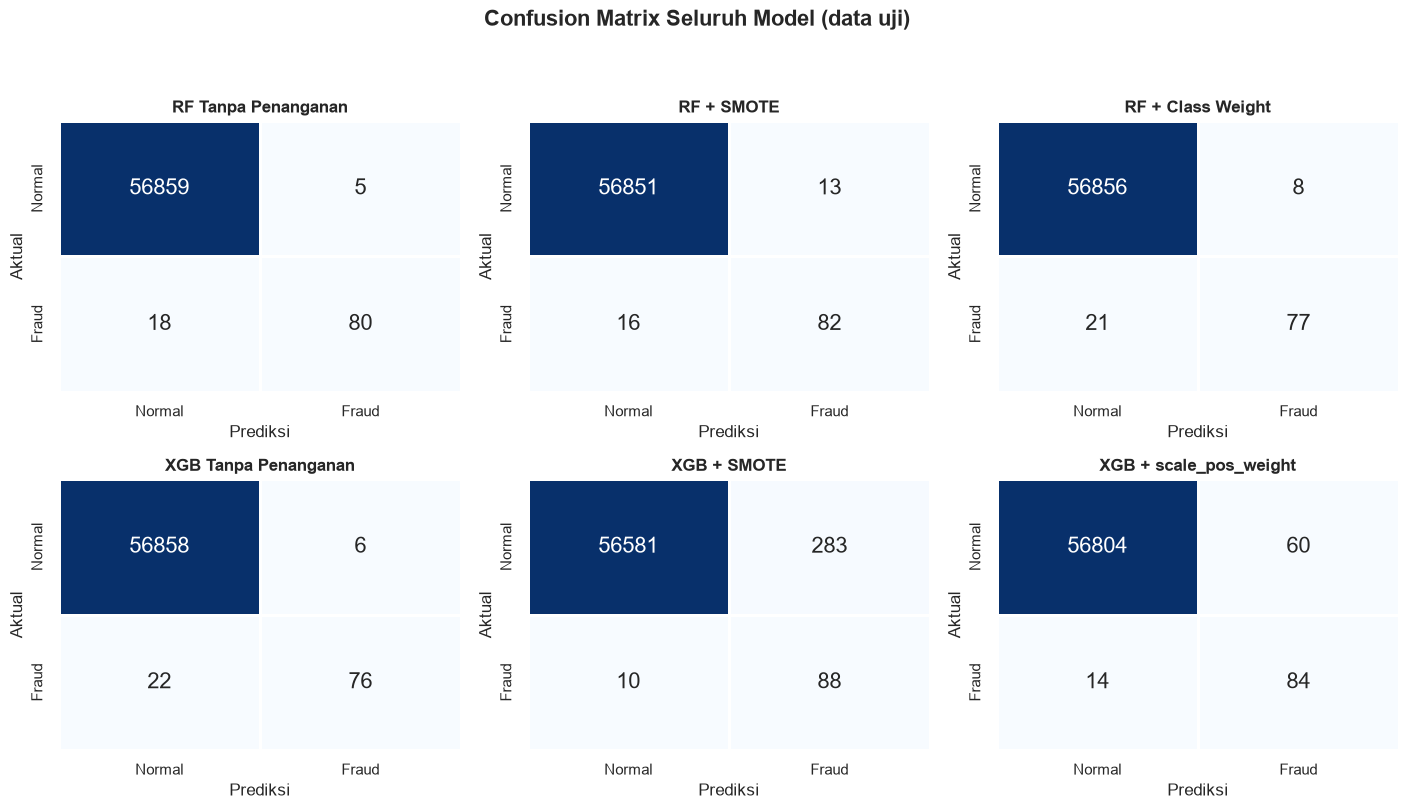

In [15]:
nama_model = list(hasil.keys())

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, nama in zip(axes.ravel(), nama_model):
    cm = hasil[nama]["cm"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                annot_kws={"size": 16}, linewidths=1)
    ax.set_title(nama, fontsize=12, weight="bold")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.set_xticklabels(["Normal", "Fraud"])
    ax.set_yticklabels(["Normal", "Fraud"])

plt.suptitle("Confusion Matrix Seluruh Model (data uji)", fontsize=16, weight="bold")
plt.tight_layout(rect=[0.03, 0.03, 0.98, 0.94])
plt.savefig("figures/fig3_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.2. Kurva ROC dan Precision-Recall

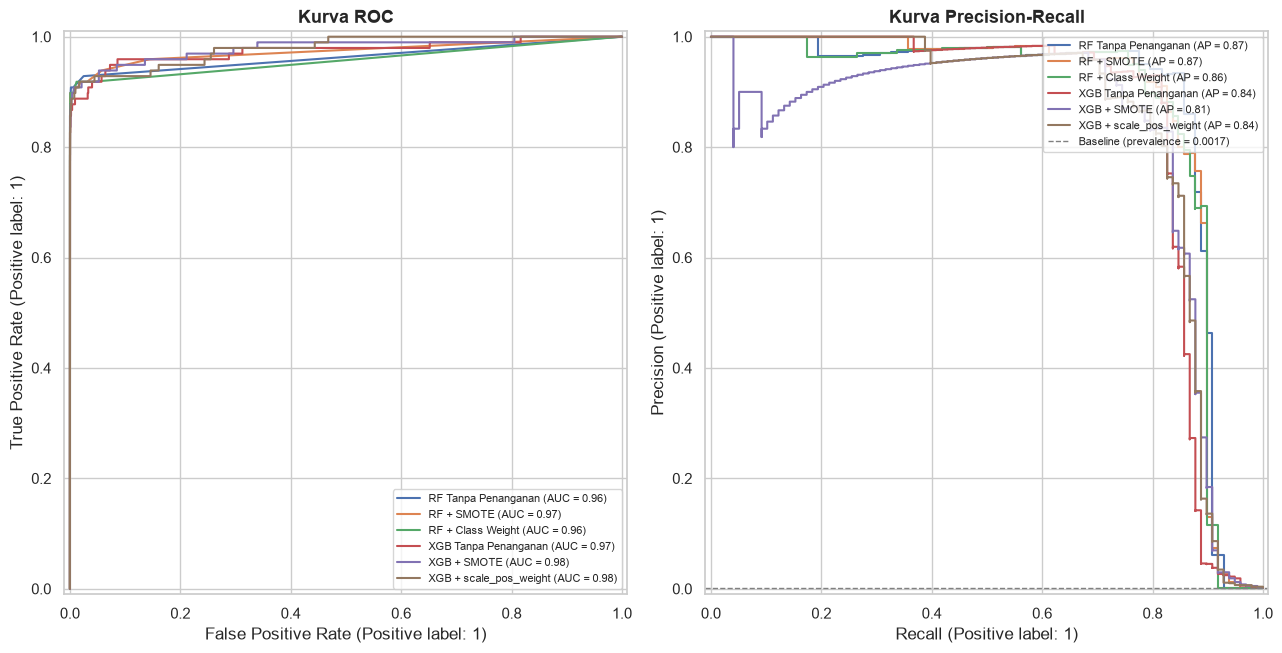

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
prevalence = y_test.mean()

for nama in nama_model:
    RocCurveDisplay.from_predictions(y_test, hasil[nama]["proba"], ax=axes[0], name=nama)
    PrecisionRecallDisplay.from_predictions(y_test, hasil[nama]["proba"], ax=axes[1], name=nama)

axes[0].set_title("Kurva ROC", fontsize=13, weight="bold")
axes[1].set_title("Kurva Precision-Recall", fontsize=13, weight="bold")
axes[1].axhline(prevalence, ls="--", c="gray", lw=1,
                label=f"Baseline (prevalence = {prevalence:.4f})")
axes[1].legend(loc="upper right", fontsize=8)
axes[0].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig("figures/fig4_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Faktor yang Paling Mempengaruhi

Biar nggak cuma kelihatan angkanya aja, saya cek juga fitur apa yang paling ngefek ke keputusan model. Random Forest nyimpan *feature importance* bawaan, tinggal diambil.

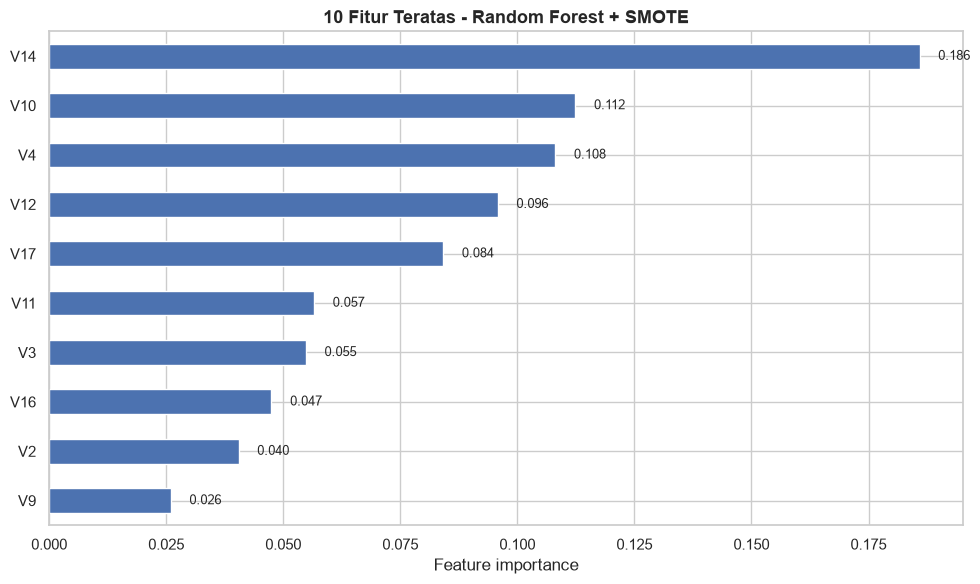

Top 10 fitur:


V14    0.1859
V10    0.1124
V4     0.1081
V12    0.0958
V17    0.0841
V11    0.0566
V3     0.0548
V16    0.0475
V2     0.0404
V9     0.0260
dtype: float64

In [17]:
best_rf = hasil["RF + SMOTE"]["model"]
imp = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
imp.head(10)[::-1].plot.barh(ax=ax, color="#4c72b0")
ax.set_title("10 Fitur Teratas - Random Forest + SMOTE", fontsize=13, weight="bold")
ax.set_xlabel("Feature importance")
for i, v in enumerate(imp.head(10)[::-1].values):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("figures/fig5_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 10 fitur:")
imp.head(10).round(4)

## 9. Pembahasan dan Kesimpulan

### 9.1. Kenapa accuracy nggak cukup

Ini yang tadi udah kebukti. Model dummy yang nggak belajar apa-apa aja dapet akurasi **99,83%**, tapi recall-nya 0. Artinya angka segitu nggak punya makna apa-apa buat kasus fraud.

Semua model di bawah ini juga akurasinya di kisaran 99,5%–99,96%, padahal performanya beda jauh. Jadi akurasi emang nggak bisa dipakai buat milih model di sini.

### 9.2. Perbandingan hasil

| Model | Precision | Recall | F1 | ROC-AUC | PR-AUC | Fraud kelewatan |
|---|---|---|---|---|---|---|
| RF Tanpa Penanganan | 0.9412 | 0.8163 | **0.8743** | 0.9630 | **0.8734** | 18 / 98 |
| RF + SMOTE | 0.8632 | 0.8367 | 0.8497 | 0.9734 | 0.8706 | 16 / 98 |
| RF + Class Weight | 0.9059 | 0.7857 | 0.8415 | 0.9573 | 0.8629 | 21 / 98 |
| XGB Tanpa Penanganan | 0.9268 | 0.7755 | 0.8444 | **0.9748** | 0.8413 | 22 / 98 |
| XGB + scale_pos_weight | 0.5833 | 0.8571 | 0.6942 | 0.9789 | 0.8404 | 14 / 98 |
| XGB + SMOTE | 0.2372 | **0.8980** | 0.3753 | 0.9794 | 0.8115 | 10 / 98 |

Data uji berisi 56.864 normal dan 98 fraud.

**Yang menarik, penanganan imbalance itu nggak otomatis bikin modelnya lebih bagus.**

- **F1 tertinggi justru di Random Forest tanpa penanganan apa-apa (0.8743).** Dia juga paling presisi (0.9412), jadi alarm palsunya paling sedikit, cuma 5 dari 56.864 transaksi normal.
- Tapi RF tanpa penanganan ini recall-nya cuma 0.8163, alias **18 kasus fraud kelewatan**.
- **SMOTE bikin recall naik dari 0.8163 ke 0.8367** dan ROC-AUC naik dari 0.9630 ke 0.9734, jadi 16 fraud kelewatan. Harganya precision turun ke 0.8632, alarm palsu naik jadi 13.
- **Class weighting justru paling buruk di antara ketiga Random Forest.** Recall-nya malah turun ke 0.7857. Di kasus ini cara paling murah itu nggak seefektif yang dikira.
- **XGBoost + SMOTE** paling agresif: recall 0.8980, cuma 10 fraud yang lolos. Tapi precision-nya anjlok ke 0.2372, artinya dari 371 alarm yang dibunyikan, 283 di antaranya palsu. F1-nya jatuh ke 0.3753 dan MCC-nya juga paling rendah (0.4601), jadi model ini sebenernya nggak sebagus yang kelihatan dari recall-nya.

### 9.3. Pilihan model

Kalau lihat dari sisi kerugian, fraud yang lolos itu cost-nya jauh lebih besar daripada false alarm, yang satu langsung jadi uang hilang, yang satu cuma bikin tim fraud-nya repot ngecek.

Berdasarkan itu, **Random Forest + SMOTE** adalah yang paling seimbang buat dipakai: recall 0.8367, ROC-AUC 0.9734, dan PR-AUC 0.8706 (terbaik kedua, cuma selisih 0.003 dari RF tanpa penanganan). Dia nangkep 2 fraud lebih banyak dari RF biasa, dan ranking probabilitasnya juga lebih bagus.

Tapi kalau kebijakannya "nggak boleh ada fraud yang lolos sama sekali", **XGB + SMOTE** bisa jadi pilihan karena cuma ngelewat 10 kasus. Konsekuensinya tim investigasi harus siap nanganin ratusan alarm palsu tiap periode.

### 9.4. Kesimpulan

1. Distribusi kelas di dataset ini emang timpang parah (0.17%), dan itu bikin accuracy jadi metrik yang nggak bermakna.
2. SMOTE berhasil ngingetin recall, tapi dampaknya beda-beda tiap model. Di Random Forest hasilnya masih masuk akal, di XGBoost justru bikin precision hancur.
3. Dari 6 model yang dicoba, **Random Forest + SMOTE** paling seimbang antara recall, precision, dan ranking probabilitasnya.
4. Resampling yang dilakukan cuma di data latih bikin hasil evaluasinya lebih bisa dipercaya, karena data uji tetep pakai distribusi asli.
5. Class weighting nggak selalu lebih baik dari SMOTE. Di percobaan ini dia justru paling lemah di kelompok Random Forest.